# Выученная политика против простых эвристик

Цель — проверить, даёт ли выученное правило $f=\pi(z)$ более высокий **тот же** риск-чувствительный функционал $J^\pi$, который используется в стационарной задаче. Сравниваем его с пятью правилами: все новые кредиты float, смесь 50/50, все fixed, постоянное действие $f_0=\pi(z_0)$ и сохранение текущей доли fixed в книге ($f=F/L$). Все политики стартуют из **одного состояния** и живут в одной среде.

Есть две проверки. (1) Переоценка каждой политики через её собственное уравнение Беллмана оценивает бессрочный рекурсивный $J^\pi$. Это приближение нейросетью; невязка и разброс между независимыми сетками обязательны для интерпретации. (2) Общие случайные траектории дают накопленные дисконтированные выплаты до 5, 10, 20 и 30 лет. Их математическое ожидание **не равно** рекурсивному риск-чувствительному $J^\pi$ и не включает хвост после последнего года; оно помогает понять денежные потоки и устойчивость ранжирования.

In [1]:
from pathlib import Path
from dataclasses import replace
import hashlib, json, math, os, sys
import numpy as np
import torch
import matplotlib.pyplot as plt

RUN_DIR = 'runs/stationary_refined3'  # папка с stationary_solution.pt
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = torch.float64
POLICY_ACTIONS = None        # None = сетка действий из чекпоинта; можно увеличить для диагностики
MC_PATHS = 128 if os.environ.get('IRRBB_NOTEBOOK_SMOKE') else 1024
MC_HORIZONS = (1, 2) if os.environ.get('IRRBB_NOTEBOOK_SMOKE') else (5, 10, 20, 30)
MC_SEED = 20261022
EVAL_SEEDS = (1943,) if os.environ.get('IRRBB_NOTEBOOK_SMOKE') else (1943, 1944)
EVAL_TRAIN_STATES = 128 if os.environ.get('IRRBB_NOTEBOOK_SMOKE') else 2048
EVAL_VALID_STATES = 64 if os.environ.get('IRRBB_NOTEBOOK_SMOKE') else 512
EVAL_ITERATIONS = 3 if os.environ.get('IRRBB_NOTEBOOK_SMOKE') else 300
EVAL_EPOCHS = 3 if os.environ.get('IRRBB_NOTEBOOK_SMOKE') else 20
EVAL_TOLERANCE = .003
EVAL_BATCH = 128
RUN_RECURSIVE_EVALUATION = True

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'continuous_time_irrbb/risk_sensitive/stationary_solver.py').exists()), None)
if root is None: raise FileNotFoundError('Запустите Jupyter внутри проекта IRRBB')
sys.path.insert(0,str(root))
risk_dir = root/'continuous_time_irrbb/risk_sensitive'
run_dir = Path(RUN_DIR).expanduser()
if not run_dir.is_absolute(): run_dir = risk_dir/run_dir
checkpoint = run_dir/'stationary_solution.pt'
if not checkpoint.exists(): raise FileNotFoundError(checkpoint)
from continuous_time_irrbb.risk_sensitive.stationary_solver import (
    StationarySolution, generate_stationary_cloud, fit_projection,
    make_operator, stationary_continuation)
solution = StationarySolution.load(checkpoint,device=DEVICE,dtype=DTYPE)
env, p, cfg = solution.environment,solution.environment.p,solution.config
POLICY_ACTIONS = cfg.action_count if POLICY_ACTIONS is None else POLICY_ACTIONS
report_path = run_dir/'report.json'
report = json.loads(report_path.read_text()) if report_path.exists() else {}
reference = report.get('reference_state',[.08,.5*p.loans,.05625*p.loans,.12*p.loans])
x0 = torch.tensor([reference],device=DEVICE,dtype=DTYPE)
env.validate_state(x0)
checkpoint_hash = hashlib.sha256(checkpoint.read_bytes()).hexdigest()[:16]
print(f'Чекпоинт: {checkpoint}\nУстройство: {DEVICE}; dt={cfg.dt}; '
      f'γ на книгу={cfg.risk_aversion_per_loan:g}; начальное состояние={reference}')
print('Диагностика исходной сети:', report.get('diagnostics',[{}])[-1])

Чекпоинт: /home/jovyan/belyakov/ir_risk/continuous_time_irrbb/risk_sensitive/runs/stationary_refined3/stationary_solution.pt
Устройство: cuda; dt=0.25; γ на книгу=10; начальное состояние=[0.1, 50.0, 5.0, 13.0]
Диагностика исходной сети: {'iteration': 500, 'projection_rmse': 0.005404875068086394, 'epochs': 16, 'bellman_rmse': 0.005081972572952509, 'bellman_q95_abs': 0.008929061703383923, 'mean_action_change': 0.00048828125}


In [ ]:
with torch.inference_mode():
    f0 = float(solution.action(x0,action_count=POLICY_ACTIONS).item())

POLICIES = {
    'learned': 'Выученная обратная связь',
    'fixed_ref': f'Постоянное f₀={f0:.3f}',
    'hold_mix': 'Сохранять F/L',
    'half': 'Всегда f=0.5',
    'all_float': 'Все новые float',
    'all_fixed': 'Все новые fixed',
}

def actions(policy, x, time, loans=None):
    if loans is None: loans=torch.full(x.shape[:-1],p.loans,device=DEVICE,dtype=DTYPE)
    if policy=='learned':
        return solution.action(x,time=time,loans=loans,action_count=POLICY_ACTIONS)
    if policy=='fixed_ref': return torch.full(x.shape[:-1],f0,device=DEVICE,dtype=DTYPE)
    if policy=='hold_mix': return (x[...,1]/loans).clamp(0,1)
    if policy=='half': return torch.full(x.shape[:-1],.5,device=DEVICE,dtype=DTYPE)
    if policy=='all_float': return torch.zeros(x.shape[:-1],device=DEVICE,dtype=DTYPE)
    if policy=='all_fixed': return torch.ones(x.shape[:-1],device=DEVICE,dtype=DTYPE)
    raise KeyError(policy)
print('Сравниваем:', ', '.join(POLICIES.values()))

## Денежные потоки на одинаковых траекториях

Для каждой стратегии используем **одни и те же** реализации шоков ставки. Суммируем знаковые выплаты владельцу с рыночным дисконтированием до указанных горизонтов. Разности считаем попарно на одинаковых траекториях: это уменьшает шум Монте-Карло. Такой график — проверка денежных потоков, **не** замена бессрочного энтропийного критерия.

In [ ]:
steps = round(max(MC_HORIZONS)/cfg.dt)
if abs(steps*cfg.dt-max(MC_HORIZONS))>1e-8: raise ValueError('Горизонты должны делиться на dt')
noise_gen = torch.Generator(device='cpu').manual_seed(MC_SEED)
common_noise = torch.randn((steps,MC_PATHS),generator=noise_gen,dtype=DTYPE).to(DEVICE)
checkpoint_steps = {round(years/cfg.dt): years for years in MC_HORIZONS}
mc_payoffs = {}
mc_mean_actions = {}
with torch.inference_mode():
    for name in POLICIES:
        state=x0.expand(MC_PATHS,-1).clone()
        discount=torch.ones(MC_PATHS,device=DEVICE,dtype=DTYPE)
        loans=torch.full_like(discount,env.p.loans)
        accumulated=torch.zeros_like(discount)
        snapshots={}
        action_sum=0.0
        for k in range(steps):
            time=k*cfg.dt
            f=actions(name,state,time,loans)
            transition=env.step(state,f,common_noise[k],cfg.dt,time=time,loans=loans,validate=False)
            accumulated += discount*transition.dividend_pv
            discount *= transition.discount
            state=transition.state
            loans=transition.next_loans
            action_sum += float(f.mean().item())
            if k+1 in checkpoint_steps:
                snapshots[checkpoint_steps[k+1]]=accumulated.cpu().numpy().copy()
        mc_payoffs[name]=snapshots
        mc_mean_actions[name]=action_sum/steps
        print(f'{POLICIES[name]}: среднее f={mc_mean_actions[name]:.3f}, '
              f'выплаты до {max(MC_HORIZONS)} лет={snapshots[max(MC_HORIZONS)].mean():.3f}')

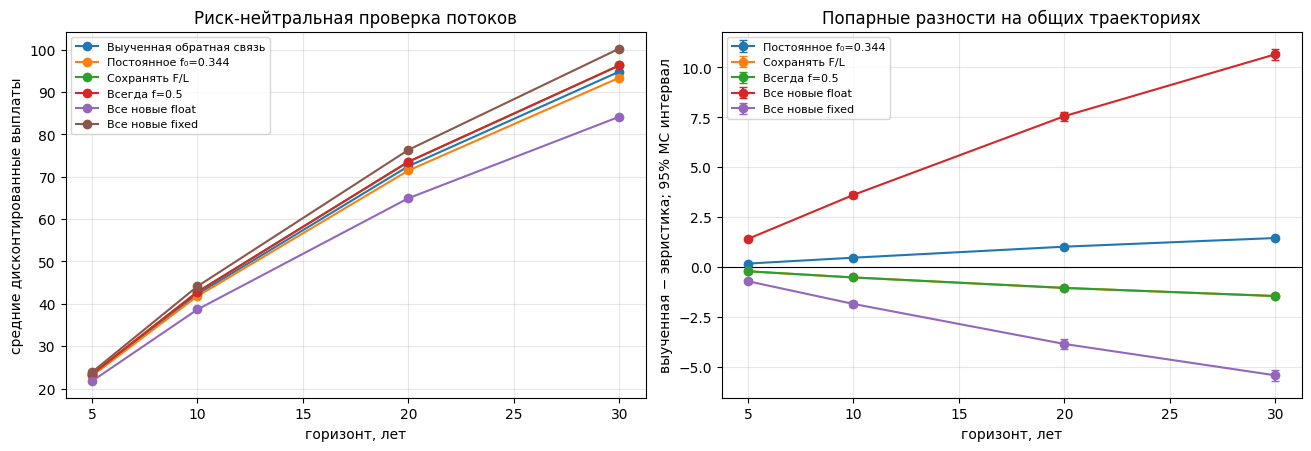

In [4]:
fig,axes=plt.subplots(1,2,figsize=(13,4.4),constrained_layout=True)
for name,label in POLICIES.items():
    means=[mc_payoffs[name][h].mean() for h in MC_HORIZONS]
    axes[0].plot(MC_HORIZONS,means,marker='o',label=label)
    if name!='learned':
        diff=[(mc_payoffs['learned'][h]-mc_payoffs[name][h]).mean() for h in MC_HORIZONS]
        se=[(mc_payoffs['learned'][h]-mc_payoffs[name][h]).std(ddof=1)/math.sqrt(MC_PATHS)
            for h in MC_HORIZONS]
        axes[1].errorbar(MC_HORIZONS,diff,yerr=1.96*np.array(se),marker='o',capsize=3,label=label)
axes[0].set(xlabel='горизонт, лет',ylabel='средние дисконтированные выплаты',
            title='Риск-нейтральная проверка потоков')
axes[1].axhline(0,color='black',lw=.8)
axes[1].set(xlabel='горизонт, лет',ylabel='выученная − эвристика; 95% MC интервал',
            title='Попарные разности на общих траекториях')
for ax in axes: ax.grid(alpha=.3);ax.legend(fontsize=8)
plt.show()

## Бессрочный риск-чувствительный функционал $J^\pi$

Для каждой **фиксированной политики** $\pi$ отдельно приближаем неподвижную точку
$$J^\pi(z)=B(z,\pi(z))+e^{-(r-g)h}\operatorname{CE}_{\bar\gamma e^{gh}}[J^\pi(z')\mid z,\pi(z)].$$
Это тот же оператор потоков, дисконтирования и энтропийного риска, что при обучении оптимальной политики, но **без максимизации по действиям при оценке стратегии**. Правило `learned` вычисляется из исходного чекпоинта и затем фиксируется как функция состояния. Все стратегии в одном повторе обучаются и проверяются на одинаковых облаках состояний. Два seed показывают устойчивость к выборке облака, но не являются доверительным интервалом. Результат кешируется рядом с чекпоинтом; изменение файла чекпоинта или настроек оценки инвалидирует кеш.

In [5]:
from copy import deepcopy
from torch import Tensor

EVAL_CONFIG = replace(cfg,train_states=EVAL_TRAIN_STATES,
                      validation_states=EVAL_VALID_STATES,
                      iterations=EVAL_ITERATIONS,epochs_per_iteration=EVAL_EPOCHS,
                      residual_tolerance=EVAL_TOLERANCE,
                      target_batch=EVAL_BATCH)
eval_settings = {'checkpoint_hash':checkpoint_hash,'seeds':EVAL_SEEDS,
                 'train_states':EVAL_TRAIN_STATES,'valid_states':EVAL_VALID_STATES,
                 'iterations':EVAL_ITERATIONS,'epochs':EVAL_EPOCHS,
                 'tolerance':EVAL_TOLERANCE,'policy_actions':POLICY_ACTIONS,
                 'dtype':str(DTYPE),'initial_state':reference}
eval_hash=hashlib.sha256(json.dumps(eval_settings,sort_keys=True).encode()).hexdigest()[:12]
cache_dir=run_dir/'policy_benchmark_cache'

def mixed_cloud(n,seed):
    broad_n=n-n//4
    broad=generate_stationary_cloud(env,broad_n,seed,EVAL_CONFIG.exploration_steps,
                                    device=torch.device(DEVICE),dtype=DTYPE)
    gen=torch.Generator(device='cpu').manual_seed(seed+10000)
    jitter=torch.randn((n-broad_n,4),generator=gen,dtype=DTYPE).to(DEVICE)
    scale=torch.tensor([.02,.12*p.loans,.015*p.loans,.04*p.loans],
                       device=DEVICE,dtype=DTYPE)
    local=x0.expand(n-broad_n,-1)+jitter*scale
    local[:,0].clamp_(min=0)
    local[:,1].clamp_(0,p.loans)
    local[:,2].clamp_(min=0)
    return torch.cat((broad,local),dim=0)

@torch.no_grad()
def fixed_policy_targets(operator,states,policy_actions,continuation):
    chunks=[]
    for xb,ab in zip(states.split(EVAL_BATCH),policy_actions.split(EVAL_BATCH)):
        chunks.append(operator.evaluate(0,xb,ab,EVAL_CONFIG.dt,continuation))
    return torch.cat(chunks)

def evaluate_policy(name,seed,train_x,valid_x):
    torch.manual_seed(seed)
    train_a=torch.cat([actions(name,part,0) for part in train_x.split(EVAL_BATCH)])
    valid_a=torch.cat([actions(name,part,0) for part in valid_x.split(EVAL_BATCH)])
    anchor_a=actions(name,x0,0)
    net=deepcopy(solution.value_net)
    operator=make_operator(env,EVAL_CONFIG,x0)
    history=[]
    stable=0
    converged=False
    for iteration in range(1,EVAL_ITERATIONS+1):
        cont=stationary_continuation(env,net)
        train_y=fixed_policy_targets(operator,train_x,train_a,cont)
        valid_y=fixed_policy_targets(operator,valid_x,valid_a,cont)
        new_net,_=fit_projection(net,train_x,train_y,valid_x,valid_y,EVAL_CONFIG)
        new_cont=stationary_continuation(env,new_net)
        with torch.no_grad():
            residual=new_net(valid_x)-fixed_policy_targets(operator,valid_x,valid_a,new_cont)
            anchor_residual=new_net(x0)-operator.evaluate(0,x0,anchor_a,cfg.dt,new_cont)
            anchor_change=(new_net(x0)-net(x0)).abs().item()
            info={'iteration':iteration,'value':float(new_net(x0).item()),
                  'bellman_rmse':float(residual.square().mean().sqrt().item()),
                  'bellman_q95':float(torch.quantile(residual.abs(),.95).item()),
                  'anchor_residual':float(anchor_residual.abs().item()),
                  'anchor_change':float(anchor_change)}
        if iteration==1 or iteration%10==0 or iteration==EVAL_ITERATIONS:
            history.append(info)
        net=new_net
        good=(info['bellman_rmse']<=EVAL_TOLERANCE and
              info['bellman_q95']<=3*EVAL_TOLERANCE and
              info['anchor_residual']<=EVAL_TOLERANCE and
              info['anchor_change']<=EVAL_TOLERANCE)
        stable=stable+1 if good else 0
        if stable>=5:
            converged=True
            break
        if iteration%100==0:
            print(f'  {name}, seed={seed}, iter={iteration}: '
                  f'J≈{info["value"]:.5f}, RMSE={info["bellman_rmse"]:.5f}',flush=True)
    tail=[h['value'] for h in history[-6:]]
    return {'policy':name,'seed':seed,'J':info['value'],'converged':converged,
            'iterations':iteration,'last':info,'tail_range':max(tail)-min(tail),
            'history':history,'settings_hash':eval_hash}

In [6]:
evaluations=[]
if RUN_RECURSIVE_EVALUATION:
    cache_dir.mkdir(parents=True,exist_ok=True)
    for seed in EVAL_SEEDS:
        train_x=mixed_cloud(EVAL_TRAIN_STATES,seed+1)
        valid_x=mixed_cloud(EVAL_VALID_STATES,seed+2)
        for name in POLICIES:
            path=cache_dir/f'{name}_seed{seed}_{eval_hash}.json'
            if path.exists():
                result=json.loads(path.read_text())
                print(f'кеш: {name}, seed={seed}')
            else:
                print(f'оцениваю {name}, seed={seed}...',flush=True)
                result=evaluate_policy(name,seed,train_x,valid_x)
                path.write_text(json.dumps(result,ensure_ascii=False,indent=2))
            evaluations.append(result)
        del train_x,valid_x
    print(f'Оценка закончена. Кеш: {cache_dir}')
else:
    print('Рекурсивная переоценка отключена; результаты ниже пропускаются.')

оцениваю learned, seed=1943...
  learned, seed=1943, iter=100: J≈132.67849, RMSE=0.00547
  learned, seed=1943, iter=200: J≈132.66080, RMSE=0.00591
  learned, seed=1943, iter=300: J≈132.66763, RMSE=0.00628
оцениваю fixed_ref, seed=1943...
  fixed_ref, seed=1943, iter=100: J≈132.55992, RMSE=0.00631
  fixed_ref, seed=1943, iter=200: J≈132.50363, RMSE=0.00631
  fixed_ref, seed=1943, iter=300: J≈132.47789, RMSE=0.00697
оцениваю hold_mix, seed=1943...
  hold_mix, seed=1943, iter=100: J≈132.36867, RMSE=0.01026
  hold_mix, seed=1943, iter=200: J≈132.30150, RMSE=0.00826
  hold_mix, seed=1943, iter=300: J≈132.25627, RMSE=0.00823
оцениваю half, seed=1943...
  half, seed=1943, iter=100: J≈132.34076, RMSE=0.00788
  half, seed=1943, iter=200: J≈132.21678, RMSE=0.00787
  half, seed=1943, iter=300: J≈132.21973, RMSE=0.00810
оцениваю all_float, seed=1943...
  all_float, seed=1943, iter=100: J≈129.50931, RMSE=0.01974
  all_float, seed=1943, iter=200: J≈128.37732, RMSE=0.01058
  all_float, seed=1943, ite

Политика                       J min       J max     Bellman RMSE max   сошлось
Выученная обратная связь       132.6676   132.6976         0.0063       0/2
Постоянное f₀=0.344            132.4779   132.5961         0.0070       0/2
Сохранять F/L                  132.2563   132.2636         0.0082       0/2
Всегда f=0.5                   132.2197   132.2585         0.0081       0/2
Все новые float                127.3422   127.8554         0.0081       0/2
Все новые fixed                124.2912   124.5663         0.0071       0/2


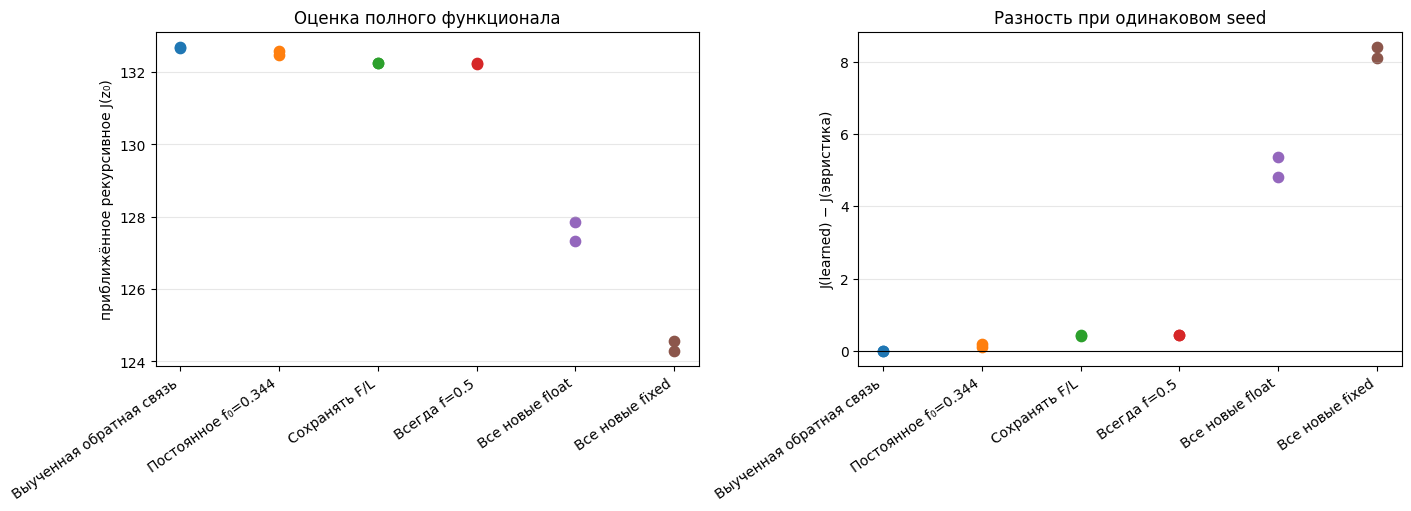

ВНИМАНИЕ: хотя бы одна политика не прошла критерии невязки. Её численный J и ранжирование близких политик нельзя считать установленными.


In [7]:
if evaluations:
    by_name={name: sorted([q for q in evaluations if q['policy']==name],
                           key=lambda z:z['seed']) for name in POLICIES}
    print('Политика                       J min       J max     Bellman RMSE max   сошлось')
    for name,label in POLICIES.items():
        q=by_name[name]
        print(f'{label:29s} {min(z["J"] for z in q):9.4f}  '
              f'{max(z["J"] for z in q):9.4f}      '
              f'{max(z["last"]["bellman_rmse"] for z in q):9.4f}       '
              f'{sum(z["converged"] for z in q)}/{len(q)}')
    fig,axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
    names=list(POLICIES)
    for j,name in enumerate(names):
        q=by_name[name]
        for z in q:
            axes[0].scatter(j,z['J'],color=f'C{j}',s=55)
            base=next(v for v in by_name['learned'] if v['seed']==z['seed'])
            axes[1].scatter(j,base['J']-z['J'],color=f'C{j}',s=55)
    axes[0].set(ylabel='приближённое рекурсивное J(z₀)',title='Оценка полного функционала')
    axes[1].axhline(0,color='black',lw=.8)
    axes[1].set(ylabel='J(learned) − J(эвристика)',title='Разность при одинаковом seed')
    for ax in axes:
        ax.set_xticks(range(len(names)),[POLICIES[n] for n in names],rotation=35,ha='right')
        ax.grid(axis='y',alpha=.3)
    plt.show()
    if any(not q['converged'] for q in evaluations):
        print('ВНИМАНИЕ: хотя бы одна политика не прошла критерии невязки. '
              'Её численный J и ранжирование близких политик нельзя считать установленными.')
    for seed in EVAL_SEEDS:
        learned=next(q for q in by_name['learned'] if q['seed']==seed)
        better=[POLICIES[n] for n in names if n!='learned'
                for q in by_name[n] if q['seed']==seed and q['J']>learned['J']]
        if better:print(f'seed={seed}: эвристики с большей оценкой J: {better}; '
                        'это повод проверить оптимальность и точность оценки.')

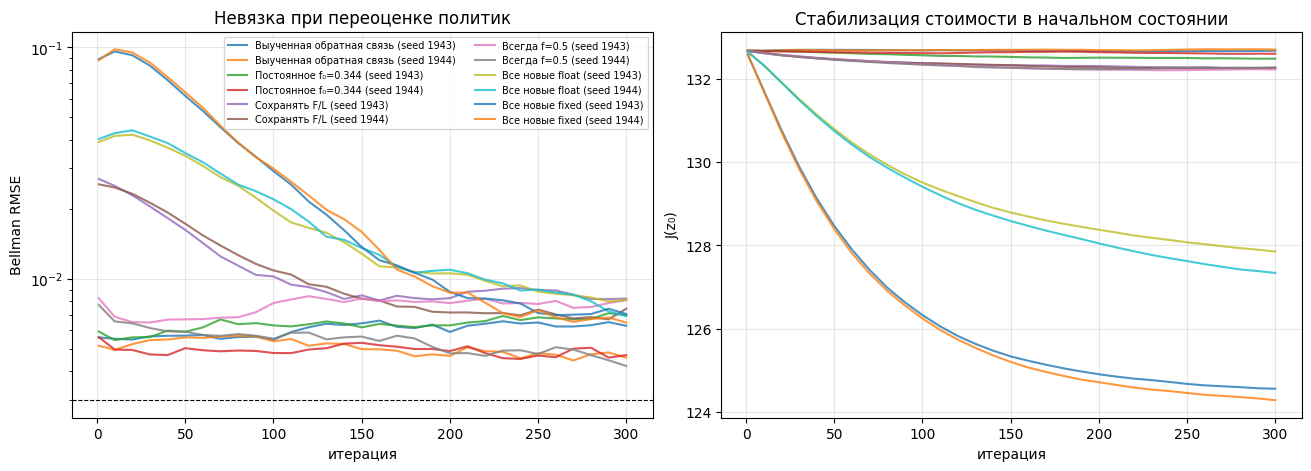

In [8]:
if evaluations:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
    for name, label in POLICIES.items():
        runs = [q for q in evaluations if q['policy'] == name]
        for z in runs:
            h = z['history']
            iterations = [v['iteration'] for v in h]
            suffix = f' (seed {z["seed"]})' if len(EVAL_SEEDS) > 1 else ''
            axes[0].plot(iterations, [v['bellman_rmse'] for v in h],
                         label=label + suffix, alpha=.8)
            axes[1].plot(iterations, [v['value'] for v in h],
                         label=label + suffix, alpha=.8)
    axes[0].axhline(EVAL_TOLERANCE, color='black', ls='--', lw=.8)
    axes[0].set(xlabel='итерация', ylabel='Bellman RMSE', yscale='log',
                title='Невязка при переоценке политик')
    axes[1].set(xlabel='итерация', ylabel='J(z₀)',
                title='Стабилизация стоимости в начальном состоянии')
    for ax in axes: ax.grid(alpha=.3)
    axes[0].legend(fontsize=7,ncol=2)
    plt.show()


**Критерий вывода.** Сравнение убедительно, когда разница $J$ сохраняет знак между seed, невязка и дрейф оценок существенно меньше этой разницы, а попарные денежные потоки не противоречат ей без объяснения эффектом неприятия риска. Бессрочная задача с рыночным дисконтированием и растущей книгой может сходиться медленно; `converged=False` или пересечение оценок между seed нельзя переименовывать в доказательство оптимальности или неоптимальности. Если одна эвристика устойчиво лучше выученной политики при том же $J$, следует дообучить либо изменить метод решения.